<a href="https://colab.research.google.com/github/abishaireddy0-hub/solar-battery-energy-optimisation/blob/main/notebooks/01_Project_setup_and_Configurarion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solar PV + Battery Energy Storage Optimisation

## Project Overview

This project develops a Python-based techno-economic optimisation
framework for integrating Solar Photovoltaic (PV) systems and
Battery Energy Storage Systems (BESS) into a commercial building.

The objective is to minimise electricity costs, maximise solar
energy utilisation, and identify the economically optimal battery
capacity.

### Project Location
Mumbai, India

### Building Type
Commercial Building

### Project Scope
1. Building electricity demand analysis
2. Solar PV generation modelling
3. Battery energy storage modelling
4. Energy management and optimisation
5. Electricity cost analysis
6. Economic feasibility assessment

**Milestone 1:** Project Setup and Configuration

## 1. Project Objectives

The main objectives of this project are:

- Analyse hourly electricity consumption of a commercial building.
- Estimate electricity generation from a rooftop solar PV system.
- Model battery charging and discharging behaviour.
- Minimise electricity purchased from the grid.
- Compare different battery storage capacities.
- Calculate electricity bill savings and investment returns.
- Identify the optimal battery capacity using an optimisation approach.

## 2. Project Directory Structure

The project follows a modular structure to maintain clean,
organised and reusable code.

solar-battery-energy-optimisation/

    data/
        raw/
        processed/

    notebooks/

    reports/

    results/

    src/
        config.py

    .gitignore
    LICENSE
    README.md
    requirements.txt

### Directory Description

- data/raw: Original downloaded datasets.
- data/processed: Cleaned and processed datasets.
- notebooks: Jupyter notebooks for analysis and modelling.
- reports: Project documentation and reports.
- results: Simulation outputs and generated figures.
- src: Python source code and configuration files.

In [1]:
# Import essential Python libraries

import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [4]:
import os
import sys
import subprocess

project_path = "/content/solar-battery-energy-optimisation"

# Clone repository if it doesn't exist
if not os.path.exists(project_path):

    print("Project folder not found. Cloning from GitHub...")

    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/abishaireddy0-hub/solar-battery-energy-optimisation.git",
            project_path
        ],
        check=True
    )

else:
    print("Project folder already exists!")

# Change working directory
os.chdir(project_path)

# Add project to Python path
if project_path not in sys.path:
    sys.path.insert(0, project_path)

print("\nCurrent working directory:")
print(os.getcwd())

print("\nProject setup successful!")

Project folder not found. Cloning from GitHub...

Current working directory:
/content/solar-battery-energy-optimisation

Project setup successful!


In [5]:
print(os.listdir())

['.gitignore', 'reports', 'README.md', 'data', 'requirements.txt', 'LICENSE', '.git', 'results', 'notebooks', 'src']


In [6]:
import src.config as config

print("Configuration imported successfully!")
print("PV Capacity:", config.PV_CAPACITY_KW, "kW")
print("Battery Capacities:", config.BATTERY_CAPACITIES_KWH)

Configuration imported successfully!
PV Capacity: 20 kW
Battery Capacities: [0, 5, 10, 15, 20, 25]


In [7]:
import src.config as config

print("Configuration imported successfully!")

print("\nPV Capacity:", config.PV_CAPACITY_KW, "kW")
print("Battery Capacities:", config.BATTERY_CAPACITIES_KWH, "kWh")
print("Battery Power:", config.BATTERY_POWER_KW, "kW")
print("Minimum SOC:", config.MIN_SOC)
print("Maximum SOC:", config.MAX_SOC)

Configuration imported successfully!

PV Capacity: 20 kW
Battery Capacities: [0, 5, 10, 15, 20, 25] kWh
Battery Power: 5 kW
Minimum SOC: 0.2
Maximum SOC: 0.9


In [8]:
# Define project directory

project_path = "/content/solar-battery-energy-optimisation"

# Change working directory
os.chdir(project_path)

# Add project directory to Python path
if project_path not in sys.path:
    sys.path.insert(0, project_path)

print("Current working directory:")
print(os.getcwd())

Current working directory:
/content/solar-battery-energy-optimisation


In [9]:
# Import project configuration

import src.config as config

print("Project configuration imported successfully!")

Project configuration imported successfully!


## 3. Initial Engineering Assumptions

The following preliminary engineering parameters are used
for developing the solar PV and battery storage model.

These values are initial project assumptions and may be
revised as the project develops.

In [10]:
# Display important project parameters

print("PROJECT CONFIGURATION")
print("=" * 45)

print("Project Name:", config.PROJECT_NAME)
print("Location:", config.LOCATION)
print("Building Type:", config.BUILDING_TYPE)

print("\nSOLAR PV SYSTEM")
print("=" * 45)

print("PV Capacity:", config.PV_CAPACITY_KW, "kW")

print("\nBATTERY SYSTEM")
print("=" * 45)

print("Battery Capacities:", config.BATTERY_CAPACITIES_KWH, "kWh")
print("Battery Power:", config.BATTERY_POWER_KW, "kW")
print("Charging Efficiency:", config.CHARGING_EFFICIENCY)
print("Discharging Efficiency:", config.DISCHARGING_EFFICIENCY)

print("\nBATTERY OPERATING LIMITS")
print("=" * 45)

print("Minimum SOC:", config.MIN_SOC)
print("Maximum SOC:", config.MAX_SOC)
print("Initial SOC:", config.INITIAL_SOC)

print("\nECONOMIC PARAMETERS")
print("=" * 45)

print("Project Lifetime:", config.PROJECT_LIFETIME_YEARS, "years")
print("Discount Rate:", config.DISCOUNT_RATE * 100, "%")

PROJECT CONFIGURATION
Project Name: Solar-Battery Energy Optimisation
Location: Mumbai, Maharashtra, India
Building Type: Commercial

SOLAR PV SYSTEM
PV Capacity: 20 kW

BATTERY SYSTEM
Battery Capacities: [0, 5, 10, 15, 20, 25] kWh
Battery Power: 5 kW
Charging Efficiency: 0.95
Discharging Efficiency: 0.95

BATTERY OPERATING LIMITS
Minimum SOC: 0.2
Maximum SOC: 0.9
Initial SOC: 0.5

ECONOMIC PARAMETERS
Project Lifetime: 10 years
Discount Rate: 10.0 %


## 4. Preliminary Battery Energy Calculation

Before developing the complete battery simulation,
we calculate the usable energy capacity of a battery.

The usable battery energy is determined by its rated capacity
and permitted State of Charge (SOC) operating range.

Formula:

E_usable = E_rated × (SOC_max - SOC_min)

Where:

- E_usable = Usable battery energy (kWh)
- E_rated = Rated battery capacity (kWh)
- SOC_max = Maximum State of Charge
- SOC_min = Minimum State of Charge

In [11]:
# Select a 10 kWh battery for demonstration

battery_capacity = 10  # kWh

# Calculate usable energy
usable_capacity = battery_capacity * (config.MAX_SOC - config.MIN_SOC)

# Calculate energy delivered after discharge losses
delivered_energy = usable_capacity * config.DISCHARGING_EFFICIENCY

print("BATTERY ENERGY CALCULATION")
print("=" * 40)

print("Rated Battery Capacity:", battery_capacity, "kWh")
print("Minimum SOC:", config.MIN_SOC * 100, "%")
print("Maximum SOC:", config.MAX_SOC * 100, "%")

print("\nUsable Battery Energy:", round(usable_capacity, 2), "kWh")
print("Energy Delivered:", round(delivered_energy, 2), "kWh")

BATTERY ENERGY CALCULATION
Rated Battery Capacity: 10 kWh
Minimum SOC: 20.0 %
Maximum SOC: 90.0 %

Usable Battery Energy: 7.0 kWh
Energy Delivered: 6.65 kWh


## 5. Battery Operating Range Visualisation

The battery cannot use its entire rated capacity because
minimum and maximum SOC limits are imposed.

The following visualisation illustrates the operating
range of the selected 10 kWh battery.

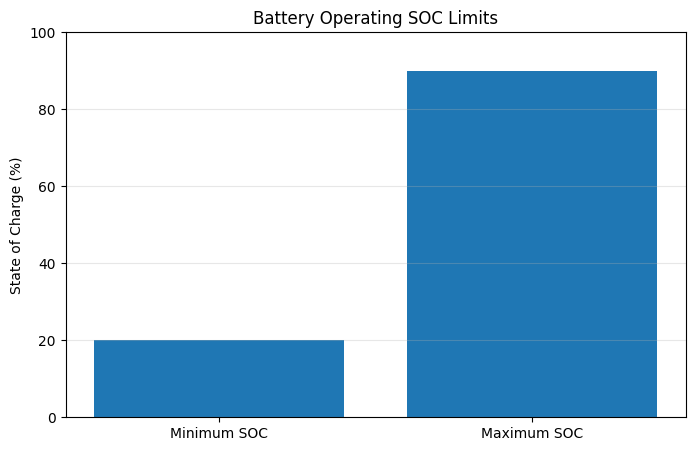

In [12]:
# Battery SOC visualisation

soc_levels = [
    config.MIN_SOC * 100,
    config.MAX_SOC * 100
]

labels = ["Minimum SOC", "Maximum SOC"]

plt.figure(figsize=(8, 5))

plt.bar(labels, soc_levels)

plt.ylabel("State of Charge (%)")
plt.title("Battery Operating SOC Limits")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

## 6. Milestone 1 Summary

The initial project setup has been completed.

### Completed Tasks

- Created the GitHub repository.
- Established the project directory structure.
- Created the central configuration module.
- Set up the Google Colab environment.
- Successfully imported project configuration.
- Verified preliminary engineering parameters.
- Calculated usable battery energy.
- Visualised battery SOC operating limits.

### Key Calculation

For a 10 kWh battery operating between 20% and 90% SOC:

Usable Energy = 10 × (0.90 - 0.20)

Usable Energy = 7 kWh

Considering 95% discharge efficiency:

Delivered Energy = 7 × 0.95

Delivered Energy = 6.65 kWh

### Conclusion

The project environment and initial engineering configuration
are ready for the next development stage.

**Next Milestone:** Building Electricity Dataset Acquisition
and Analysis.